# Rendeiro et al. 2020 — CLL (10x) · Step 02: EMT-TF Expression
**Unconditional final step** (produced regardless of gate outcome; renumbered to 02 after the Gate 1
NO-GO). EMT transcription-factor expression overlaid on the malignant manifold, using the reference's
**categorical thresholded-expresser** style (expressers colored over a grey manifold), gated on
detectable expression, spanning the Snail/Zeb/Twist, FOXC and PRRX families. VIM is a mesenchymal marker,
not a TF, and is excluded.

In [1]:
import os, sys
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth  = os.path.join(*(['..']*4))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
print(adata.shape, '| geometry: no trajectory (Gate 1 NO-GO — per-patient archipelago)')

(18657, 14889) | geometry: no trajectory (Gate 1 NO-GO — per-patient archipelago)


### Candidate panel & detection gating
Score each candidate EMT-TF by the fraction of malignant cells with detectable (>0) expression; retain
those expressed in >3% of cells and display the two most broadly detected.

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
absent  = [g for g in panel if g not in adata.var_names]
print('candidate TFs present:', present)
print('candidate TFs absent :', absent)
def vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
rows = []
for g in present:
    v = vec(g); expr = v > 0
    rows.append((g, round(float(expr.mean()), 4), round(float(v[expr].mean()) if expr.any() else 0.0, 3)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_in_expressers']).sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
show = ok.TF.tolist()[:2]
print('\nexpressed TFs (>3%):', ok.TF.tolist())
print('displayed (top-2 by detection):', show)

candidate TFs present: ['SNAI1', 'ZEB1', 'ZEB2', 'FOXC1', 'PRRX1']
candidate TFs absent : ['SNAI2', 'TWIST1', 'TWIST2', 'FOXC2', 'PRRX2']
   TF  frac_expr  mean_in_expressers
 ZEB2     0.1235               0.555
 ZEB1     0.0381               0.523
SNAI1     0.0005               0.442
FOXC1     0.0005               0.578
PRRX1     0.0002               0.519

expressed TFs (>3%): ['ZEB2', 'ZEB1']
displayed (top-2 by detection): ['ZEB2', 'ZEB1']


overlay thresholds (upper quartile among expressers): {'ZEB2': 0.647, 'ZEB1': 0.618}
cells shown: {'ZEB2': 575, 'ZEB1': 178}
saved expression.pdf


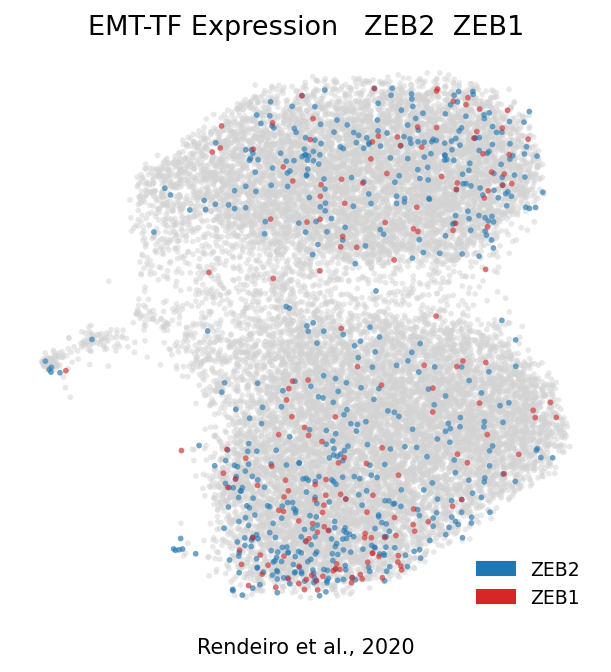

In [4]:
# categorical thresholded-expresser overlay on a grey manifold (reference 06 style)
thr = {}
for g in show:
    v = vec(g); pos = v[v > 0]
    thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in show}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g], 3) for g in show})
print('cells shown:', {g: int(sel[g].sum()) for g in show})
colors = {show[0]: 'tab:blue', show[1]: 'tab:red'} if len(show) == 2 else {show[0]: 'tab:blue'}
order = sorted(show, key=lambda g: -int(sel[g].sum()))
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=30, alpha=.5, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.6, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='sample', size=30, alpha=0, legend_loc=None, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
lbl = '  '.join(f'{g}' for g in show)
ax.set_title('EMT-TF Expression   ' + lbl, size=13)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=colors[g], label=g) for g in show], loc='lower right', frameon=False, fontsize=9)
ax.text(.5, -.05, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
plt.show()
print('saved expression.pdf')

**Note.** With no continuous trajectory (Gate 1 NO-GO), these TFs are read as static expression across
the patient-segregated malignant compartment, not as a root→terminus gradient. The displayed factors are
the most broadly detected EMT-TFs in this CLL dataset.